# Phase 2: Comparative Topic Modeling & Ground-Truth Alignment

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120

ROOT = Path("..").resolve()
RESULTS_DIR = ROOT / "results"

summary = pd.read_csv(RESULTS_DIR / "topic_comparison_summary.csv")
metrics = pd.read_csv(RESULTS_DIR / "model_metrics.csv")
display(metrics)
display(summary)

,model,n_docs,n_topics,npmi_coherence
0,TF-IDF + NMF,25000,10,0.2317
1,BERTopic,25000,10,0.1395


,model,topic_id,count,share_pct,top_words
0,TF-IDF + NMF,0,2197,8.79,"mortgage, home, modification, sale, property, ..."
1,TF-IDF + NMF,1,4605,18.42,"report, remove, dispute, equifax, experian, ac..."
2,TF-IDF + NMF,2,2797,11.19,"debt, collect, owe, collector, letter, debt co..."
3,TF-IDF + NMF,3,4651,18.60,"charge, fee, check, money, balance, pay, overd..."
4,TF-IDF + NMF,4,2372,9.49,"call, number, phone, day, phone number, work, ..."
5,TF-IDF + NMF,5,728,2.91,"fargo, wells, wells fargo, check, fargo home, ..."
6,TF-IDF + NMF,6,2341,9.36,"payment, late, pay, month, late payment, late ..."
7,TF-IDF + NMF,7,2745,10.98,"loan, pay, interest, rate, student, student lo..."
8,TF-IDF + NMF,8,1842,7.37,"collection, agency, bill, collection agency, p..."
9,TF-IDF + NMF,9,722,2.89,"chase, check, call chase, contact chase, morga..."


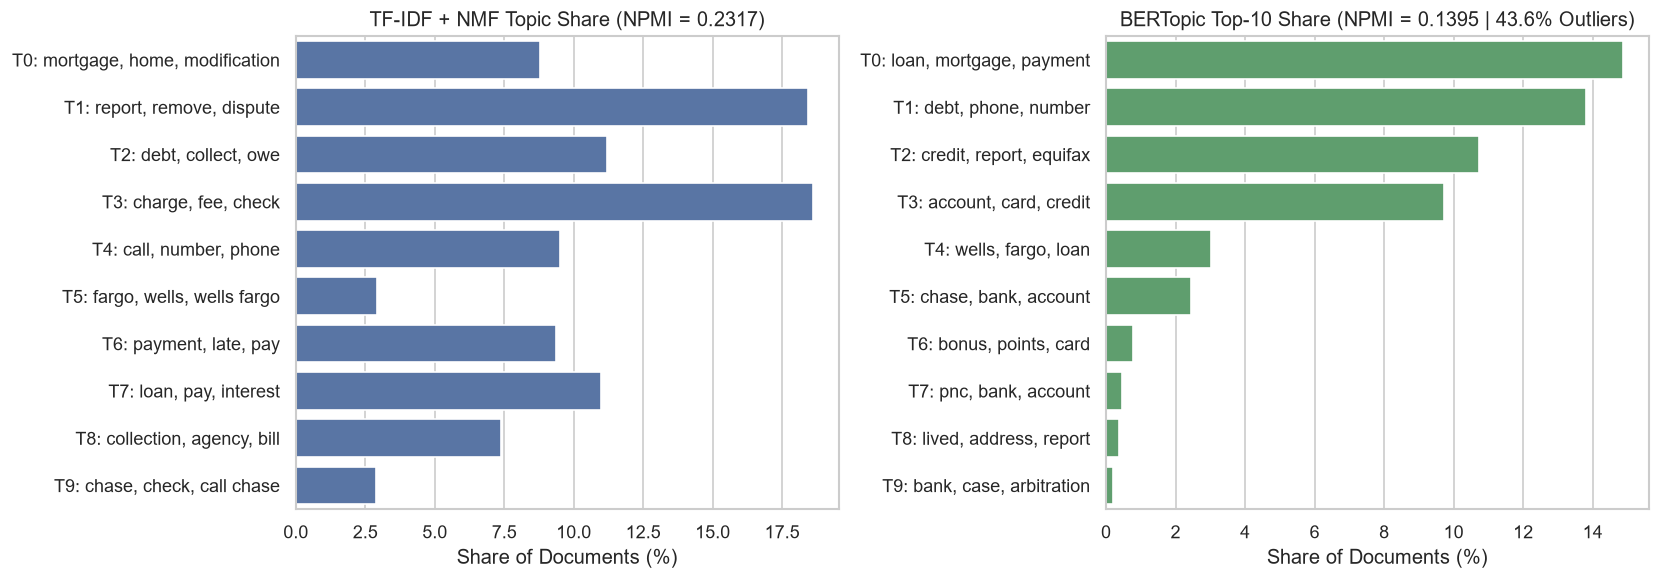

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
nmf_df = summary[summary["model"] == "TF-IDF + NMF"].copy()
nmf_df["label"] = nmf_df.apply(lambda r: f"T{r['topic_id']}: {', '.join(r['top_words'].split(', ')[:3])}", axis=1)

bert_df = summary[summary["model"] == "BERTopic"].copy()
bert_df["label"] = bert_df.apply(lambda r: f"T{r['topic_id']}: {', '.join(r['top_words'].split(', ')[:3])}", axis=1)

sns.barplot(data=nmf_df, x="share_pct", y="label", ax=axes[0], color="#4C72B0")
axes[0].set_title(f"TF-IDF + NMF Topic Share (NPMI = {metrics.loc[0, 'npmi_coherence']:.4f})")
axes[0].set_xlabel("Share of Documents (%)")
axes[0].set_ylabel("")

sns.barplot(data=bert_df, x="share_pct", y="label", ax=axes[1], color="#55A868")
axes[1].set_title(f"BERTopic Top-10 Share (NPMI = {metrics.loc[1, 'npmi_coherence']:.4f} | 43.6% Outliers)")
axes[1].set_xlabel("Share of Documents (%)")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

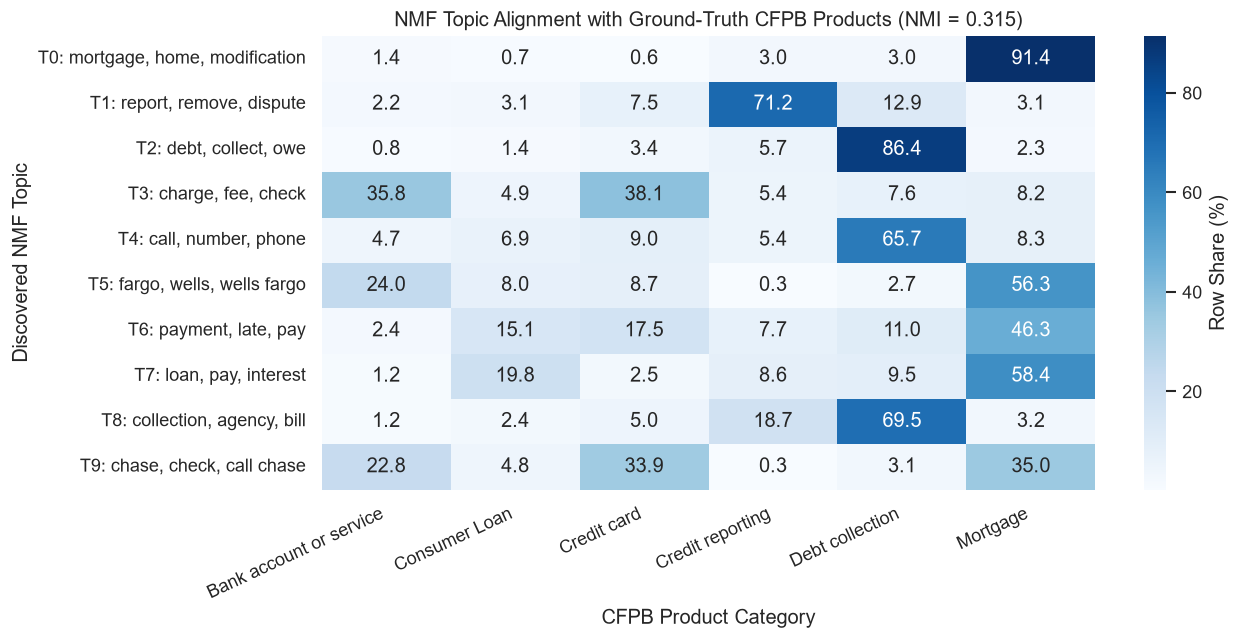

In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF
from sklearn.metrics import normalized_mutual_info_score

df = pd.read_csv(RESULTS_DIR / "complaints_clean.csv").dropna(subset=["tokens", "clean_text"])
df = df.sample(n=25000, random_state=42).reset_index(drop=True)

extra_stopwords = ["not", "no", "never", "tell", "say", "receive", "send", "time", "information", "know", "want", "ask", "go", "get"]
vec = TfidfVectorizer(max_features=8000, min_df=10, max_df=0.85, ngram_range=(1, 2), stop_words=extra_stopwords)
X = vec.fit_transform(df["tokens"])
nmf = NMF(n_components=10, random_state=42, init="nndsvda", max_iter=400)
df["nmf_topic"] = nmf.fit_transform(X).argmax(axis=1)

top_prods = df["product"].value_counts().head(6).index
sub = df[df["product"].isin(top_prods)]
nmi = normalized_mutual_info_score(sub["product"], sub["nmf_topic"])

ct = pd.crosstab(sub["nmf_topic"], sub["product"], normalize="index") * 100
ct.index = [f"T{i}: {', '.join(nmf_df.loc[nmf_df['topic_id']==i, 'top_words'].values[0].split(', ')[:3])}" for i in ct.index]

plt.figure(figsize=(11, 5.5))
sns.heatmap(ct, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "Row Share (%)"})
plt.title(f"NMF Topic Alignment with Ground-Truth CFPB Products (NMI = {nmi:.3f})")
plt.xlabel("CFPB Product Category")
plt.ylabel("Discovered NMF Topic")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()